import libraries

In [34]:
from langgraph.graph import START, END, StateGraph
from dotenv import load_dotenv
from typing import TypedDict, Annotated
from langchain_groq import ChatGroq
from pydantic import BaseModel, Field
import operator
from IPython.display import display, Image

In [35]:
load_dotenv()

True

create model and schema for structure model

In [36]:
model = ChatGroq(model="meta-llama/llama-4-scout-17b-16e-instruct")

In [37]:
class EvalutionSchema(BaseModel):
    feedback:str= Field(description="Provide feedback on the provided essay text")
    score:int=Field(description="Provide Score out of 10", ge=0, le=10)

In [38]:
structured_model = model.with_structured_output(EvalutionSchema)

Create State for Essay

In [39]:
class UPSCEssay(TypedDict):
    essay_txt:str
    analysis_feedback:str
    clarity_feedback:str
    depth_feedback:str
    overall_feedback:str
    individual_score:Annotated[list[int],operator.add]# this is reducer to add/merge state data rather than overwriting. operator is used because we can not use arithmetic operators line '+'
    avg_score:float
    #annotated is used for -

create Node Functionas

In [40]:
def evaluate_analysis(state:UPSCEssay):
    essay = state["essay_txt"]
    prompt=f"Evaluate this essay- {essay} on the basis of language analysis and provide feedback and score for it"
    response = structured_model.invoke(prompt)
    print(response.score)
    print(type(response.score))
    return{"analysis_feedback":response.feedback,"individual_score":[response.score]}

def evaluate_clarity(state:UPSCEssay):
    essay = state["essay_txt"]
    prompt=f"Evaluate this essay- {essay} on the basis of clarity of thoughts and provide feedback and score for it"
    response = structured_model.invoke(prompt)
    return{"clarity_feedback":response.feedback,"individual_score":[response.score]}

def evaluate_depth(state:UPSCEssay):
    essay = state["essay_txt"]
    prompt=f"Evaluate this essay- {essay} on the basis of depth and provide feedback and score for it"
    response = structured_model.invoke(prompt)
    return{"depth_feedback":response.feedback,"individual_score":[response.score]}

def final_evaluation(state:UPSCEssay):
    avg_score = sum(state["individual_score"])/len(state["individual_score"])
    
    prompt = f"Provide summary feedback for the essay on the basis of language feedback {state['analysis_feedback']}, clarity feedback {state['clarity_feedback']} and depth feedback {state['depth_feedback']}."

    response=model.invoke(prompt).content
    return{"overall_feedback":response,"avg_score":avg_score}

create graph

In [41]:
graph = StateGraph(UPSCEssay)

In [42]:
graph.add_node("Evaluate_Analysis", evaluate_analysis)
graph.add_node("Evaluate_Clarity", evaluate_clarity)
graph.add_node("Evaluate_Depth", evaluate_depth)
graph.add_node("Final_Evaluation", final_evaluation)

#add edges
graph.add_edge(START,"Evaluate_Analysis")
graph.add_edge(START,"Evaluate_Clarity")
graph.add_edge(START,"Evaluate_Depth")
graph.add_edge("Evaluate_Analysis","Final_Evaluation")
graph.add_edge("Evaluate_Clarity","Final_Evaluation")
graph.add_edge("Evaluate_Depth","Final_Evaluation")
graph.add_edge("Final_Evaluation",END)

In [43]:
workflow=graph.compile()

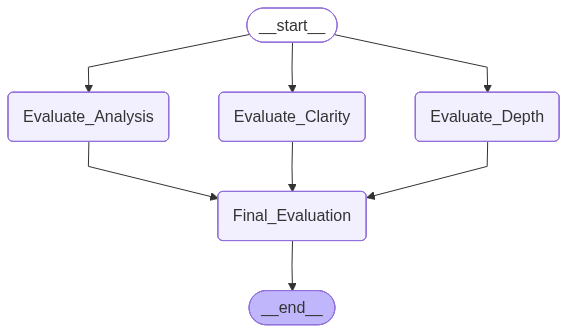

In [44]:
Image(workflow.get_graph().draw_mermaid_png())

In [45]:
essay1="""Corruption remains one of the most persistent challenges to India's governance, economic development, and social justice. It refers to the misuse of public office or authority for private gain. Despite significant progress in legislation, digital governance, and institutional reforms, corruption continues to affect various sectors, reducing public trust and hindering inclusive development.

One of the primary causes of corruption is excessive bureaucratic discretion combined with weak accountability. Complex procedures, delays in service delivery, political interference, and inadequate transparency create opportunities for bribery and misuse of power. Additionally, electoral financing, nepotism, and low ethical standards further perpetuate corrupt practices.

The consequences of corruption are far-reaching. It diverts public resources from essential sectors such as healthcare, education, and infrastructure, thereby affecting the welfare of citizens, especially the poor. Corruption discourages investment, increases the cost of doing business, and weakens economic growth. Moreover, it undermines the rule of law, erodes public confidence in democratic institutions, and widens social and economic inequalities.

India has undertaken several measures to combat corruption. Laws such as the Prevention of Corruption Act, the establishment of the Lokpal and Lokayuktas, the Right to Information (RTI) Act, and the digitization of government services have improved transparency and accountability. Initiatives like Direct Benefit Transfer (DBT), e-procurement, and online grievance redressal systems have reduced human intervention, thereby minimizing opportunities for corruption.

However, legal measures alone are insufficient. Strengthening independent institutions, ensuring swift investigation and prosecution of corruption cases, protecting whistleblowers, reforming political funding, and promoting ethical values in public life are equally important. Citizen participation, media vigilance, and the use of technology such as artificial intelligence and blockchain can further enhance transparency and reduce corruption.

In conclusion, corruption is not merely a legal issue but a challenge to good governance and sustainable development. Eliminating corruption requires a collective effort involving government, institutions, civil society, and citizens. As former Prime Minister Lal Bahadur Shastri aptly stated, "The preservation of freedom is not the task of soldiers alone. The whole nation has to be strong." Similarly, the fight against corruption demands integrity, accountability, and active participation from every stakeholder. Only then can India achieve the ideals of transparent governance and equitable development envisioned in its Constitution."""

In [46]:
initial_state={"essay_txt":essay1}
final_state= workflow.invoke(initial_state)

8
<class 'int'>


In [47]:
print(final_state)

{'essay_txt': 'Corruption remains one of the most persistent challenges to India\'s governance, economic development, and social justice. It refers to the misuse of public office or authority for private gain. Despite significant progress in legislation, digital governance, and institutional reforms, corruption continues to affect various sectors, reducing public trust and hindering inclusive development.\n\nOne of the primary causes of corruption is excessive bureaucratic discretion combined with weak accountability. Complex procedures, delays in service delivery, political interference, and inadequate transparency create opportunities for bribery and misuse of power. Additionally, electoral financing, nepotism, and low ethical standards further perpetuate corrupt practices.\n\nThe consequences of corruption are far-reaching. It diverts public resources from essential sectors such as healthcare, education, and infrastructure, thereby affecting the welfare of citizens, especially the p